# BT4012 Kaggle — EDA
Exploring the Elliptic-style bitcoin tx data before modelling.

Files: `train.csv` (steps 1–35, labelled + unknown), `test.csv` (steps 36–49), `txs_edgelist.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

## Load data
train.csv is ~460MB so reading it takes a bit. Cast feats to float32 to save memory.

In [2]:
feats = [f'feat_{i}' for i in range(1, 166)]
dtypes = {f: 'float32' for f in feats}

train = pd.read_csv('../data/train.csv', dtype=dtypes)
test = pd.read_csv('../data/test.csv', dtype=dtypes)
edges = pd.read_csv('../data/txs_edgelist.csv')
sample_sub = pd.read_csv('../data/sample_submission.csv')

print('train', train.shape)
print('test ', test.shape)
print('edges', edges.shape)

train (141772, 168)
test  (15329, 168)
edges (234355, 2)


In [3]:
train.head()

,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19,feat_20,feat_21,feat_22,feat_23,...,feat_142,feat_143,feat_144,feat_145,feat_146,feat_147,feat_148,feat_149,feat_150,feat_151,feat_152,feat_153,feat_154,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,-0.167933,-0.049707,-0.164402,-0.028741,-0.035391,-0.042955,-0.013282,-0.057195,-0.169609,-0.171154,-0.174473,-1.373657,-1.371460,-0.139731,-0.148912,...,-0.171601,-0.458162,-0.423588,-0.440883,-1.015963,-1.016230,-0.968903,-0.375715,0.759748,-0.768329,1.488113,1.487932,-0.216814,-0.605631,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,-0.167948,-0.049707,-0.164417,-0.028741,-0.035391,-0.042955,-0.013282,-0.055327,-0.169757,-0.171477,-0.174490,0.887058,0.884557,-0.139731,-0.148912,...,-0.168742,-0.263290,-0.186389,-0.250875,-1.015963,-1.016230,-0.968903,0.146997,1.366287,-0.464773,-1.116918,-1.116948,-0.216814,0.634272,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,-0.168576,-0.049707,-0.165054,-0.028741,-0.035391,-0.042955,-0.013282,-0.055298,-0.170400,-0.172217,-0.175227,0.887058,0.884557,-0.139729,-0.148911,...,-0.168742,-0.192468,-0.099790,-0.182133,-1.015963,-1.016230,-0.968903,-1.421138,-0.453330,-1.375441,-1.116918,-1.116948,-0.216814,0.407161,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,NaN
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782743,12.414557,-0.163645,-0.115831,0.043598,-0.163905,1.059993,2.397457,-0.063200,-0.013282,4.800240,0.174329,-0.172908,0.619399,-0.243300,-0.243452,-0.139732,-0.146895,...,-0.163577,-0.456561,-0.424672,-0.436915,0.143001,0.142525,-0.425896,-1.421138,-1.059868,-1.071885,0.185597,0.185492,-0.216814,-0.617907,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,0.0
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,0.041399,0.935886,-0.098695,1.203038,0.988902,0.341693,-0.013282,-0.057392,0.058329,-0.032930,-0.042709,0.065455,0.324947,-0.139732,-0.148854,...,-0.168742,-0.442156,-0.416540,-0.418273,0.367605,0.392035,-0.968903,-1.943850,-1.059868,-1.678997,0.185597,0.185492,-0.169472,-0.470592,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,NaN


In [4]:
# test has an extra 'index' col -> that's what the submission uses, not txId
print(test.columns[:4].tolist())
sample_sub.head()

['index', 'txId', 'time_step', 'feat_1']


,index,target
0,0,0.5
1,1,0.5
2,2,0.5
3,3,0.5
4,4,0.5


In [5]:
# missing values / duplicates
print('nulls in features (train):', train[feats].isna().sum().sum())
print('nulls in features (test):', test[feats].isna().sum().sum())
print('dup txIds train:', train.txId.duplicated().sum(), '| overlap train/test:', len(set(train.txId) & set(test.txId)))

nulls in features (train): 0
nulls in features (test): 0
dup txIds train: 0 | overlap train/test: 0


## Labels
`label`: 1 = illicit, 0 = licit, NaN = unknown

In [6]:
train['label'].value_counts(dropna=False)

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

In [7]:
labelled = train[train.label.notna()].copy()
labelled['label'] = labelled.label.astype(int)
print(f'labelled: {len(labelled)} ({len(labelled)/len(train):.1%} of train)')
print(f'illicit rate among labelled: {labelled.label.mean():.3f}')

labelled: 31235 (22.0% of train)
illicit rate among labelled: 0.117


## Time steps
Train = steps 1–35, test = 36–49. Want to see how the illicit rate moves over time (drift).

In [8]:
print('train steps:', train.time_step.min(), '-', train.time_step.max())
print('test steps :', test.time_step.min(), '-', test.time_step.max())

per_step = train.groupby('time_step').agg(
    n=('txId', 'size'),
    n_labelled=('label', lambda s: s.notna().sum()),
    n_illicit=('label', lambda s: (s == 1).sum()),
)
per_step['illicit_rate'] = per_step.n_illicit / per_step.n_labelled
per_step

train steps: 1 - 35
test steps : 36 - 49


,n,n_labelled,n_illicit,illicit_rate
time_step,,,,
1,7880,2147,17,0.007918
2,4544,1117,18,0.016115
3,6621,1279,11,0.008600
4,5693,1440,30,0.020833
5,6803,1882,8,0.004251
6,4328,485,5,0.010309
7,6048,1203,102,0.084788
8,4457,1165,67,0.057511
9,4996,778,248,0.318766


/tmp/ipykernel_358/2146456540.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test.assign(label='test'),


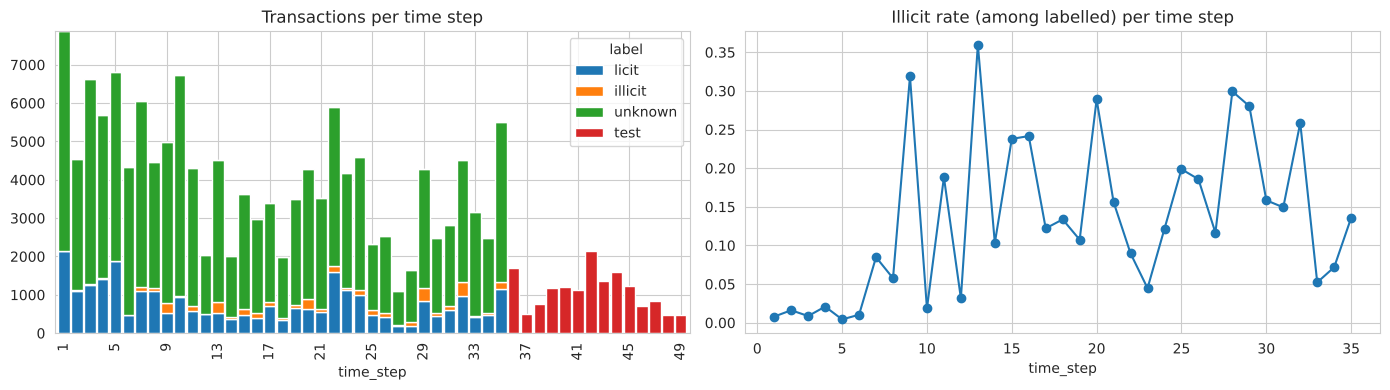

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

counts = pd.concat([
    train.assign(label=train.label.map({0: 'licit', 1: 'illicit'}).fillna('unknown')),
    test.assign(label='test'),
]).groupby(['time_step', 'label']).size().unstack(fill_value=0)
counts[['licit', 'illicit', 'unknown', 'test']].plot(kind='bar', stacked=True, ax=axes[0], width=0.9)
axes[0].set_title('Transactions per time step')
axes[0].set_xticks(range(0, 49, 4)); axes[0].set_xticklabels(range(1, 50, 4))

per_step.illicit_rate.plot(ax=axes[1], marker='o')
axes[1].set_title('Illicit rate (among labelled) per time step')
plt.tight_layout(); plt.show()

In [10]:
# test size per step - test looks like it's only the *labelled* txs of steps 36-49
test.time_step.value_counts().sort_index()

time_step
36    1708
37     498
38     756
39    1183
40    1211
41    1132
42    2154
43    1370
44    1591
45    1221
46     712
47     846
48     471
49     476
Name: count, dtype: int64

## Graph / edgelist
Edges txId1 -> txId2 = output of txId1 spent by txId2.

In [11]:
tmap = pd.concat([train[['txId', 'time_step']], test[['txId', 'time_step']]]).set_index('txId').time_step
edges['ts1'] = edges.txId1.map(tmap)
edges['ts2'] = edges.txId2.map(tmap)

both = edges.ts1.notna() & edges.ts2.notna()
print('edges with both ends in train/test:', both.sum())
print('edges crossing time steps        :', (edges.ts1[both] != edges.ts2[both]).sum())
print('edges with one end missing       :', (edges.ts1.isna() ^ edges.ts2.isna()).sum())
print('edges with both ends missing     :', (edges.ts1.isna() & edges.ts2.isna()).sum())

all_nodes = pd.unique(pd.concat([edges.txId1, edges.txId2]))
missing_nodes = set(all_nodes) - set(tmap.index)
print('nodes in edgelist but in neither file:', len(missing_nodes))

edges with both ends in train/test: 175918
edges crossing time steps        : 0
edges with one end missing       : 24245
edges with both ends missing     : 34192
nodes in edgelist but in neither file: 46668


In [12]:
# which steps do those missing nodes hang off? -> if all 36-49, they're the unlabelled test-period txs that were dropped
nb_steps = pd.concat([edges.loc[edges.ts1.isna(), 'ts2'], edges.loc[edges.ts2.isna(), 'ts1']]).dropna()
nb_steps.value_counts().sort_index()

36.0    2844
37.0    1194
38.0     927
39.0     992
40.0    1932
41.0    1935
42.0    3382
43.0    2216
44.0    1718
45.0    1934
46.0    1705
47.0    1796
48.0    1017
49.0     653
Name: count, dtype: int64

So the unlabelled txs from steps 36–49 aren't in either file - they only show up as IDs in the edgelist.
Implication: degree can be computed for every node from the edgelist, but neighbour-feature aggregates
for test nodes can only use the other test nodes. Train-side features should be built the same way or they won't match.

In [13]:
indeg = edges.txId2.value_counts()
outdeg = edges.txId1.value_counts()
for df in (train, test):
    df['in_deg'] = df.txId.map(indeg).fillna(0).astype(int)
    df['out_deg'] = df.txId.map(outdeg).fillna(0).astype(int)

labelled = train[train.label.notna()].copy()
labelled['label'] = labelled.label.astype(int)
labelled.groupby('label')[['in_deg', 'out_deg']].describe().T

/tmp/ipykernel_358/4006144192.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['in_deg'] = df.txId.map(indeg).fillna(0).astype(int)
/tmp/ipykernel_358/4006144192.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['out_deg'] = df.txId.map(outdeg).fillna(0).astype(int)
/tmp/ipykernel_358/4006144192.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To 

label                     0            1
in_deg  count  27591.000000  3644.000000
        mean       1.830379     1.254391
        std        6.115934     7.225918
        min        0.000000     0.000000
        25%        0.000000     0.000000
        50%        1.000000     1.000000
        75%        1.000000     1.000000
        max      284.000000   173.000000
out_deg count  27591.000000  3644.000000
        mean       1.148382     0.754665
        std        3.781589     0.555132
        min        0.000000     0.000000
        25%        0.000000     0.000000
        50%        1.000000     1.000000
        75%        1.000000     1.000000
        max      472.000000     2.000000

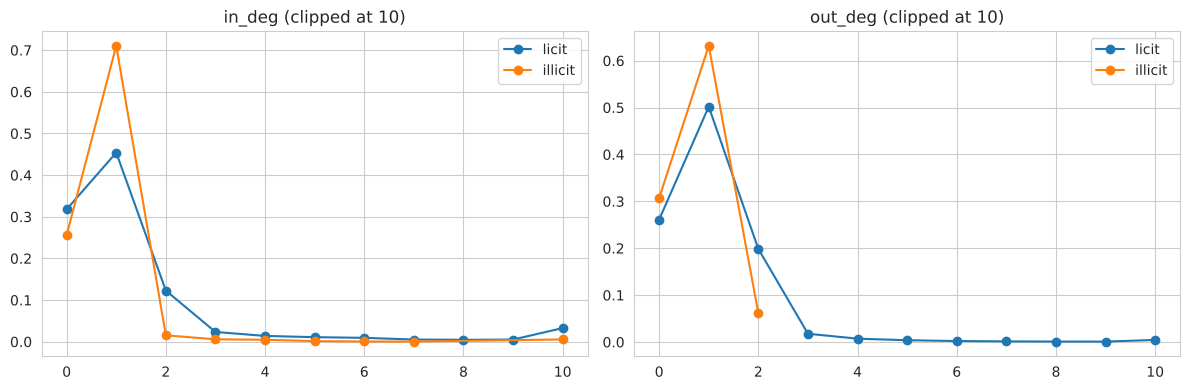

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['in_deg', 'out_deg']):
    for lab, name in [(0, 'licit'), (1, 'illicit')]:
        vc = labelled.loc[labelled.label == lab, col].clip(upper=10).value_counts(normalize=True).sort_index()
        ax.plot(vc.index, vc.values, marker='o', label=name)
    ax.set_title(f'{col} (clipped at 10)'); ax.legend()
plt.tight_layout(); plt.show()

In [15]:
# do illicit txs connect to illicit txs? (label homophily on labelled-labelled edges)
lab_map = labelled.set_index('txId').label
e = edges.assign(l1=edges.txId1.map(lab_map), l2=edges.txId2.map(lab_map)).dropna(subset=['l1', 'l2'])
pd.crosstab(e.l1, e.l2, normalize='index')

l2,0.0,1.0
l1,,
0.0,0.973311,0.026689
1.0,0.440235,0.559765


## Features
feat_1–93 should be local, feat_94–165 aggregated (1-hop neighbour stats), going by the original Elliptic layout - check.

In [16]:
local = feats[:93]
agg = feats[93:]
train[feats].describe().T.sample(10, random_state=0)

,count,mean,std,min,25%,50%,75%,max
feat_46,141772.0,-0.026927,0.883186,-0.227203,-0.227203,-0.227203,-0.226317,11.263429
feat_52,141772.0,0.020290,1.039608,-0.414036,-0.414017,-0.413864,-0.233003,7.999066
feat_109,141772.0,-0.136243,0.297970,-0.205434,-0.194817,-0.183594,-0.155425,10.411701
feat_8,141772.0,0.019083,1.129079,-0.163646,-0.163515,-0.161930,-0.138658,73.354568
feat_74,141772.0,0.011469,1.059562,-2.428426,-0.140763,-0.140763,-0.140763,2.146899
feat_63,141772.0,0.007661,0.992152,-1.315388,-1.315388,0.443354,0.923011,0.923011
feat_6,141772.0,-0.005162,0.994618,-0.113002,-0.113002,-0.113002,-0.113002,54.565178
feat_57,141772.0,-0.005315,1.034651,-2.831431,0.052956,0.052956,0.052956,2.937343
feat_138,141772.0,0.018851,1.101787,-0.301754,-0.301548,-0.298937,-0.252212,11.463401
feat_164,141772.0,0.027960,0.968482,-1.760926,-0.120613,-0.120613,0.133844,1.519700


In [17]:
# features that are near-constant
std = train[feats].std()
print('near-constant feats:', std[std < 1e-6].index.tolist())

near-constant feats: []


In [18]:
# univariate AUC of each feature on labelled train - quick look at what's informative
from sklearn.metrics import roc_auc_score
uni = pd.Series({f: roc_auc_score(labelled.label, labelled[f]) for f in feats + ['in_deg', 'out_deg']})
uni_strength = (uni - 0.5).abs().sort_values(ascending=False)
uni[uni_strength.index[:20]]

feat_53     0.143192
feat_55     0.160340
feat_90     0.163298
feat_5      0.182999
feat_14     0.183078
feat_29     0.186763
feat_23     0.186827
feat_132    0.189213
feat_60     0.190119
feat_66     0.192349
feat_41     0.193288
feat_47     0.193477
feat_142    0.801188
feat_49     0.202745
feat_43     0.202794
feat_89     0.206259
feat_25     0.208136
feat_31     0.208140
feat_18     0.222289
feat_91     0.233600
dtype: float64

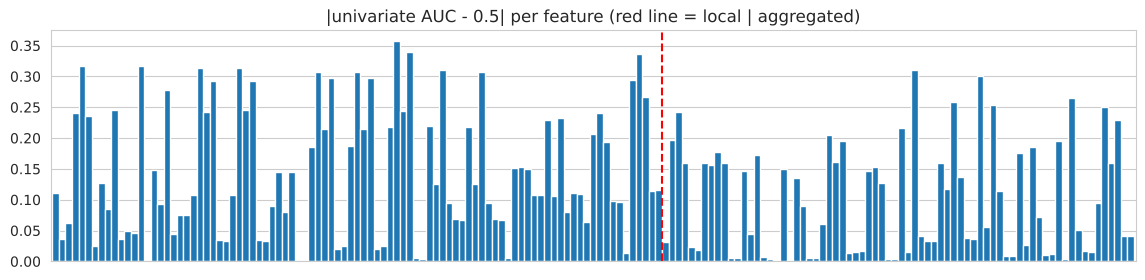

In [19]:
fig, ax = plt.subplots(figsize=(14, 3))
(uni[feats] - 0.5).abs().plot(kind='bar', ax=ax, width=1)
ax.axvline(92.5, color='red', ls='--')
ax.set_xticks([]); ax.set_title('|univariate AUC - 0.5| per feature (red line = local | aggregated)')
plt.show()

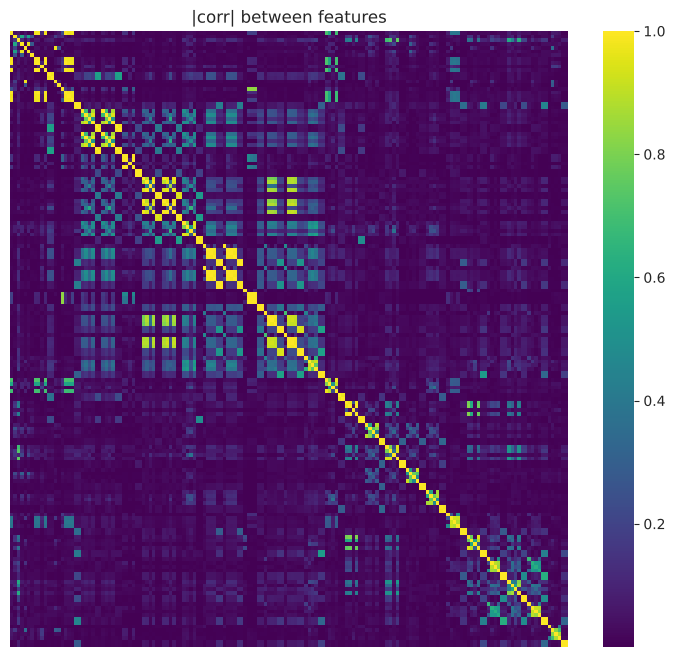

feature pairs with |corr| > 0.95: 106


In [20]:
# correlation structure - lots of redundancy expected among the aggregated ones
corr = train[feats].sample(20000, random_state=0).corr().abs()
plt.figure(figsize=(9, 8))
sns.heatmap(corr, cmap='viridis', xticklabels=False, yticklabels=False)
plt.title('|corr| between features'); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
print('feature pairs with |corr| > 0.95:', (upper > 0.95).sum().sum())

## Drift: train vs test
If feature distributions shift a lot after step 35 the model will struggle. Adversarial-validation style check per feature.

In [21]:
shift = pd.Series({f: abs(roc_auc_score(
    np.r_[np.zeros(len(train)), np.ones(len(test))],
    np.r_[train[f].values, test[f].values]) - 0.5) for f in feats})
shift.sort_values(ascending=False).head(15)

feat_101    0.498613
feat_103    0.498509
feat_100    0.498102
feat_136    0.496953
feat_139    0.483642
feat_137    0.446577
feat_2      0.399597
feat_109    0.388017
feat_107    0.379222
feat_113    0.334908
feat_115    0.329912
feat_106    0.329033
feat_151    0.313504
feat_3      0.313179
feat_142    0.282363
dtype: float64

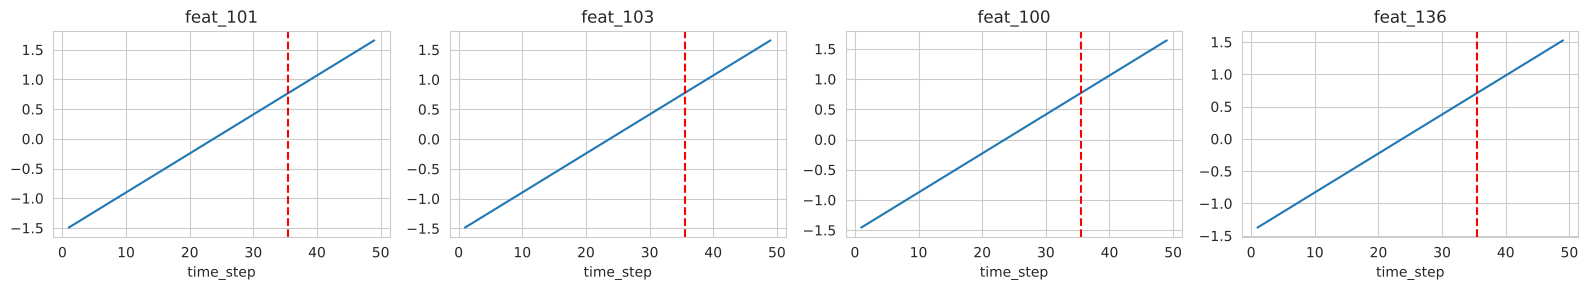

In [22]:
top = shift.sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, f in zip(axes, top):
    full = pd.concat([train[['time_step', f]], test[['time_step', f]]])
    full.groupby('time_step')[f].median().plot(ax=ax)
    ax.axvline(35.5, color='red', ls='--'); ax.set_title(f)
plt.tight_layout(); plt.show()

## Notes / next steps
- Validation must be temporal (e.g. train on steps ≤ 25, validate on 26–35), not random k-fold, since nodes in the same step are linked.
- Don't feed `time_step` to the model - test steps are never seen.
- Degree features are safe (same edgelist for train and test). Neighbour aggregates need to match what's available at test time.